In [1]:
# ============================================
# Imports
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import seaborn as sns

In [2]:
# ============================================
# Loading the original corrupted dataset
# ============================================

from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/ML_assignments_with_Abdul/house_pricing_ml_exercise.csv'


df_raw = pd.read_csv(file_path)

# Displaying the first rows
df_raw.head(4)

Mounted at /content/drive


,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
0,H0001,Frankfurt,Westend,Apartment,3,1,79.2,0,2004,Excellent,1,1.5,6.6,2.6,No,No,D,675000,1
1,H0002,Frankfurt,Gallus,Terraced House,5,2,127.3,514.9,1979,Average,2,4.1,7.4,3.6,No,Yes,D,716000,1
2,H0003,Frankfurt,Bockenheim,Apartment,2,1,45.8 sqm,0,2004,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,0
3,H0004,Hamburg,Harburg,Terraced House,5,2,182.5,529.9,2019,Needs Renovation,2,20.2,8.9,4.2,Yes,Yes,C,622000,1


In [3]:
# ============================================
# Making a copy
# ============================================

df = df_raw.copy()

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (1208, 19)

Columns:
['house_id', 'city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony', 'energy_rating', 'sale_price_eur', 'high_price']


In [4]:
# ============================================
# Inspecting the data
# ============================================

display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate complete rows:")
print(df.duplicated().sum())

,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
0,H0001,Frankfurt,Westend,Apartment,3,1,79.2,0,2004,Excellent,1,1.5,6.6,2.6,No,No,D,675000,1
1,H0002,Frankfurt,Gallus,Terraced House,5,2,127.3,514.9,1979,Average,2,4.1,7.4,3.6,No,Yes,D,716000,1
2,H0003,Frankfurt,Bockenheim,Apartment,2,1,45.8 sqm,0,2004,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,0
3,H0004,Hamburg,Harburg,Terraced House,5,2,182.5,529.9,2019,Needs Renovation,2,20.2,8.9,4.2,Yes,Yes,C,622000,1
4,H0005,Cologne,Sülz,Detached House,3,1,98.1,507.0,1979,Good,1,0.4,7.5,4.2,Yes,Yes,B,780000,1



Data types:
house_id                   object
city                       object
neighborhood               object
property_type              object
bedrooms                   object
bathrooms                  object
living_area_sqm            object
lot_size_sqm               object
year_built                 object
condition                  object
parking_spaces              int64
distance_city_center_km    object
school_rating_1_10         object
crime_rate_1_10            object
has_garden                 object
has_balcony                object
energy_rating              object
sale_price_eur              int64
high_price                  int64
dtype: object

Missing values:
house_id                    0
city                        0
neighborhood                0
property_type               0
bedrooms                   17
bathrooms                  18
living_area_sqm            27
lot_size_sqm               36
year_built                 26
condition                  28
parking_sp

In [5]:
# ============================================
# Inspecting categorical inconsistencies
# ============================================

categorical_columns = [
    "city",
    "neighborhood",
    "property_type",
    "condition",
    "has_garden",
    "has_balcony",
    "energy_rating"
]

for col in categorical_columns:
    print("\n" + "=" * 60)
    print(col)
    print(df[col].value_counts(dropna=False))


city
city
Hamburg       214
Berlin        205
Frankfurt     197
Cologne       189
Munich        189
Leipzig       170
frankfurt       5
leipzig         4
Berln           4
HAMBURG         4
Hambug          3
BERLIN          3
LEIPZIG         3
Frankfurt       3
Colgne          2
Koeln           2
Frankfrut       2
Münich          2
munich          2
Leipzg          2
cologne         1
berlin          1
hamburg         1
Name: count, dtype: int64

neighborhood
neighborhood
Kalk               43
Charlottenburg     42
Neukölln           41
Sachsenhausen      40
Winterhude         40
                   ..
Charlottenbur       1
Kalk                1
Lindenthal          1
sülz                1
Charlottenburg      1
Name: count, Length: 65, dtype: int64

property_type
property_type
Apartment          549
Detached House     260
Terraced House     191
Semi-Detached      153
apartment           12
Apartmnt            10
APARTMENT            9
Terraced Hse         5
Detatched House      4
Detach

In [6]:
# ============================================
# Cleaning numerical columns
# ============================================

numeric_columns_to_clean = [
    "bedrooms",
    "bathrooms",
    "living_area_sqm",
    "lot_size_sqm",
    "year_built",
    "parking_spaces",
    "distance_city_center_km",
    "school_rating_1_10",
    "crime_rate_1_10"
]

for col in numeric_columns_to_clean:

    # Convert "?" to missing
    df[col] = df[col].replace("?", np.nan)

    # Remove text accidentally stored in numeric columns
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.replace(" baths", "", regex=False)
        .str.replace("m2", "", regex=False)
    )

    # Convert to numeric
    # Invalid values become NaN
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [7]:
# ============================================
# Standardising categorical text
# ============================================

categorical_text_columns = [
    "city",
    "neighborhood",
    "property_type",
    "condition",
    "energy_rating"
]

for col in categorical_text_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .replace("nan", np.nan)
    )

In [8]:
# ============================================
# Fixing city names
# ============================================

city_mapping = {
    "frankfrut": "frankfurt",
    "hambug": "hamburg",
    "berln": "berlin",
    "colgne": "cologne",
    "koeln": "cologne",
    "münich": "munich",
    "leipzg": "leipzig"
}

df["city"] = df["city"].replace(city_mapping)

print(df["city"].value_counts(dropna=False))

city
hamburg      222
berlin       213
frankfurt    207
cologne      194
munich       193
leipzig      179
Name: count, dtype: int64


In [9]:
# ============================================
# Fixing property types
# ============================================

property_mapping = {
    "apartmnt": "apartment",
    "detatched house": "detached house",
    "detached": "detached house",
    "terraced hse": "terraced house",
    "terrace house": "terraced house",
    "semi detached": "semi-detached",
    "semi-detatched": "semi-detached"
}

df["property_type"] = df["property_type"].replace(property_mapping)

print(df["property_type"].value_counts(dropna=False))

property_type
apartment         580
detached house    269
terraced house    202
semi-detached     157
Name: count, dtype: int64


In [10]:
# ============================================
# Fixing "conditions"
# ============================================

condition_mapping = {
    "gud": "good",
    "averge": "average",
    "excelent": "excellent",
    "needs renovaton": "needs renovation",
    "renovation needed": "needs renovation",
    "?": np.nan
}

df["condition"] = df["condition"].replace(condition_mapping)

print(df["condition"].value_counts(dropna=False))

condition
good                487
average             358
excellent           186
needs renovation    146
NaN                  31
Name: count, dtype: int64


In [11]:
# ============================================
# Fixing energy ratings
# ============================================

energy_mapping = {
    "dd": "d",
    "?": np.nan
}

df["energy_rating"] = df["energy_rating"].replace(energy_mapping)

print(df["energy_rating"].value_counts(dropna=False))

energy_rating
c      264
d      234
b      202
e      136
a      124
f      111
a+      56
g       43
NaN     35
b+       3
Name: count, dtype: int64


In [12]:
# ============================================
# Convering YEs/No variables
# ============================================

def convert_boolean(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in ["yes", "y", "true", "1"]:
        return 1

    if value in ["no", "n", "false", "0"]:
        return 0

    return np.nan


df["has_garden"] = df["has_garden"].map(convert_boolean)
df["has_balcony"] = df["has_balcony"].map(convert_boolean)

print("Garden:")
print(df["has_garden"].value_counts(dropna=False))

print("\nBalcony:")
print(df["has_balcony"].value_counts(dropna=False))

Garden:
has_garden
0    640
1    568
Name: count, dtype: int64

Balcony:
has_balcony
1    757
0    451
Name: count, dtype: int64


In [13]:
# ============================================
# Fixing neighborhood spelling variants
# ============================================

neighborhood_mapping = {
    "bockenhei": "bockenheim",
    "bogenhause": "bogenhausen",
    "charlottenbur": "charlottenburg",
    "connewit": "connewitz",
    "ehrenfel": "ehrenfeld",
    "gallu": "gallus",
    "giesin": "giesing",
    "gohli": "gohlis",
    "grüna": "grünau",
    "harbur": "harburg",
    "kreuzber": "kreuzberg",
    "nippe": "nippes",
    "norden": "nordend",
    "panko": "pankow",
    "wandsbe": "wandsbek"
}

df["neighborhood"] = df["neighborhood"].replace(
    neighborhood_mapping
)

In [14]:
# ============================================
# Handling remaining pd.NA safely
# ============================================

# pandas nullable missing values are replaced with regular NumPy NaN
# so that scikit-learn can process them safely.

for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].replace({pd.NA: np.nan})

In [15]:
# ============================================
# Removing duplicate property records
# (ignoring "house_id")
# ============================================

before = len(df)

df = df.drop_duplicates(
    subset=[col for col in df.columns if col != "house_id"]
).copy()

after = len(df)

print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", after)
print("Duplicates removed:", before - after)

Rows before duplicate removal: 1208
Rows after duplicate removal: 1200
Duplicates removed: 8


In [16]:
# ============================================
# Creating the classification target
# ============================================

# high_price = 1 if sale price >= €500,000
# otherwise 0

df["high_price"] = (
    df["sale_price_eur"] >= 500000
).astype(int)

print(df["high_price"].value_counts())
print(df["high_price"].value_counts(normalize=True))

high_price
1    761
0    439
Name: count, dtype: int64
high_price
1    0.634167
0    0.365833
Name: proportion, dtype: float64


In [17]:
# ============================================
# Final data inspection
# ============================================

print("Final shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nData types:")
print(df.dtypes)

Final shape: (1200, 19)

Missing values:
house_id                    0
city                        0
neighborhood                0
property_type               0
bedrooms                   22
bathrooms                  22
living_area_sqm            49
lot_size_sqm               47
year_built                 37
condition                  31
parking_spaces              0
distance_city_center_km    36
school_rating_1_10         36
crime_rate_1_10            40
has_garden                  0
has_balcony                 0
energy_rating              34
sale_price_eur              0
high_price                  0
dtype: int64

Data types:
house_id                    object
city                        object
neighborhood                object
property_type               object
bedrooms                   float64
bathrooms                  float64
living_area_sqm            float64
lot_size_sqm               float64
year_built                 float64
condition                   object
parking_space

In [18]:
# ============================================
# Defining features
# (ignoring some)
# ============================================

features = [
    col for col in df.columns
    if col not in [
        "house_id",
        "sale_price_eur",
        "high_price"
    ]
]

X = df[features]

print("Features:")
print(features)

Features:
['city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony', 'energy_rating']


In [19]:
# ===============================================
# Identifying numerical and categorical features
# ===============================================

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony']

Categorical features:
['city', 'neighborhood', 'property_type', 'condition', 'energy_rating']


In [20]:
# ============================================
# Creating preprocessing pipeline
# ============================================

# Scaling not required for Decision Trees and Random Forests

numeric_preprocessor_tree = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

categorical_preprocessor_tree = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        )
    )
])

preprocessor_tree = ColumnTransformer([
    (
        "numeric",
        numeric_preprocessor_tree,
        numeric_features
    ),
    (
        "categorical",
        categorical_preprocessor_tree,
        categorical_features
    )
])

In [21]:
# ============================================
# DECISION TREE REGRESSION
# Preparing regression target and split
# ============================================

y_reg = df["sale_price_eur"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train_reg))
print("Testing observations:", len(X_test_reg))

Training observations: 960
Testing observations: 240


In [22]:
# ============================================
# Creating evaluation function
# ============================================

def evaluate_regression(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    results = {
        "Train MAE": mean_absolute_error(
            y_train,
            train_predictions
        ),

        "Train RMSE": mean_squared_error(
            y_train,
            train_predictions
        ) ** 0.5,

        "Train R2": r2_score(
            y_train,
            train_predictions
        ),

        "Test MAE": mean_absolute_error(
            y_test,
            test_predictions
        ),

        "Test RMSE": mean_squared_error(
            y_test,
            test_predictions
        ) ** 0.5,

        "Test R2": r2_score(
            y_test,
            test_predictions
        )
    }

    return results

In [23]:
# ============================================
# Testing three Decision Trees
# ============================================

tree_reg_configs = {

    "Shallow tree": {
        "max_depth": 5,
        "min_samples_split": 10,
        "min_samples_leaf": 5
    },

    "Medium tree": {
        "max_depth": 10,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },

    "Deep tree": {
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    }
}

tree_reg_results = []

tree_reg_models = {}

for name, params in tree_reg_configs.items():

    model = Pipeline([
        (
            "preprocessor",
            preprocessor_tree
        ),

        (
            "model",
            DecisionTreeRegressor(
                random_state=42,
                **params
            )
        )
    ])

    results = evaluate_regression(
        model,
        X_train_reg,
        X_test_reg,
        y_train_reg,
        y_test_reg
    )

    tree_reg_models[name] = model

    results["Configuration"] = name

    tree_reg_results.append(results)


tree_reg_results_df = pd.DataFrame(tree_reg_results)

display(
    tree_reg_results_df[
        [
            "Configuration",
            "Train MAE",
            "Train RMSE",
            "Train R2",
            "Test MAE",
            "Test RMSE",
            "Test R2"
        ]
    ]
)

,Configuration,Train MAE,Train RMSE,Train R2,Test MAE,Test RMSE,Test R2
0,Shallow tree,140702.182310,186365.181511,0.808109,164646.355929,229826.371387,0.678211
1,Medium tree,63901.721831,91459.626530,0.953785,172903.080669,242878.213565,0.640624
2,Deep tree,0.000000,0.000000,1.000000,186233.333333,258640.854597,0.592464


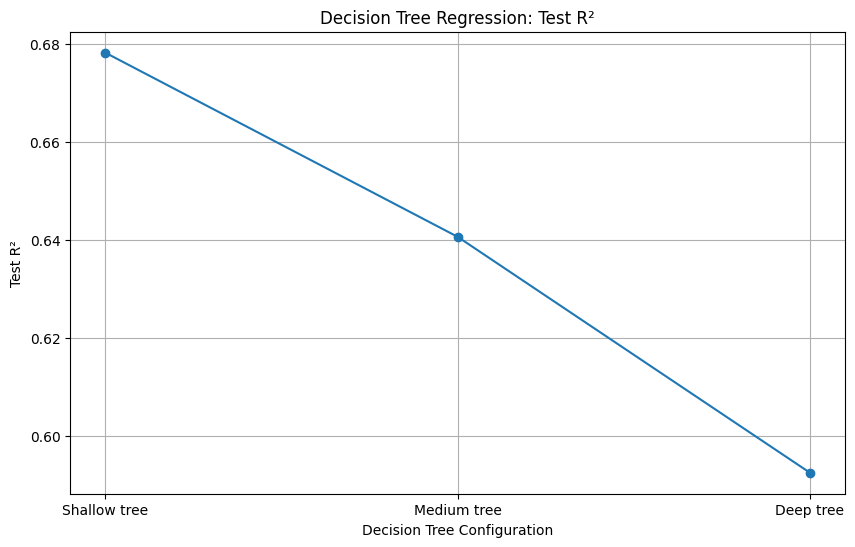

In [24]:
# ============================================
# Plotting Decision Tree performance
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    tree_reg_results_df["Configuration"],
    tree_reg_results_df["Test R2"],
    marker="o"
)

plt.xlabel("Decision Tree Configuration")
plt.ylabel("Test R²")
plt.title("Decision Tree Regression: Test R²")
plt.grid(True)

plt.show()

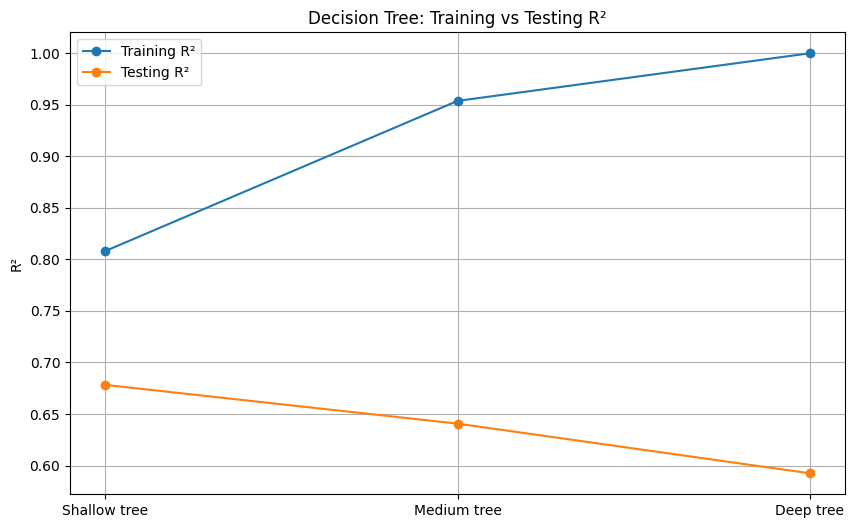

In [25]:
# ============================================
# Visualising overfitting
# ============================================

plt.figure(figsize=(10, 6))

x = np.arange(len(tree_reg_results_df))

plt.plot(
    x,
    tree_reg_results_df["Train R2"],
    marker="o",
    label="Training R²"
)

plt.plot(
    x,
    tree_reg_results_df["Test R2"],
    marker="o",
    label="Testing R²"
)

plt.xticks(
    x,
    tree_reg_results_df["Configuration"]
)

plt.ylabel("R²")
plt.title("Decision Tree: Training vs Testing R²")
plt.legend()
plt.grid(True)

plt.show()

In [26]:
# ============================================
# RANDOM FOREST REGRESSION
# Testing Random Forest configurations
# ============================================

rf_reg_configs = {

    "RF 100 trees": {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },

    "RF 300 trees": {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },

    "RF tuned": {
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_leaf": 2,
        "max_features": 0.7
    }
}

rf_reg_results = []

rf_reg_models = {}

for name, params in rf_reg_configs.items():

    model = Pipeline([
        (
            "preprocessor",
            preprocessor_tree
        ),

        (
            "model",
            RandomForestRegressor(
                random_state=42,
                n_jobs=-1,
                **params
            )
        )
    ])

    results = evaluate_regression(
        model,
        X_train_reg,
        X_test_reg,
        y_train_reg,
        y_test_reg
    )

    rf_reg_models[name] = model

    results["Configuration"] = name

    rf_reg_results.append(results)


rf_reg_results_df = pd.DataFrame(rf_reg_results)

display(
    rf_reg_results_df[
        [
            "Configuration",
            "Test MAE",
            "Test RMSE",
            "Test R2"
        ]
    ]
)

,Configuration,Test MAE,Test RMSE,Test R2
0,RF 100 trees,134889.875000,183363.661605,0.795168
1,RF 300 trees,135302.847222,182791.376555,0.796445
2,RF tuned,133728.534273,182442.096596,0.797222


In [27]:
# ============================================
# Comparison with Week 1's results
# ============================================

# ============================================================
# WEEK 1 - REPRODUCTION OF ORIGINAL NOTEBOOK
# Linear Regression
# ============================================================


# ============================================================
# IMPORTING LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

from google.colab import drive

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# MOUNTING GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")


# ============================================================
# FINDING THE DATASET IN GOOGLE DRIVE
# ============================================================

import os

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):

    for file in files:

        if file == "house_pricing_ml_exercise.csv":

            matches.append(
                os.path.join(root, file)
            )


if len(matches) == 0:

    raise FileNotFoundError(
        "house_pricing_ml_exercise.csv "
        "was not found in Google Drive."
    )


print("Dataset found:")

for path in matches:
    print(path)


# Using the first matching file
file_path = matches[0]


# ============================================================
# LOADING THE ORIGINAL DATASET
# ============================================================

df_raw = pd.read_csv(file_path)

print("\nOriginal dataset shape:")
print(df_raw.shape)


# ============================================================
# CREATING CLEANING COPY
# ============================================================

df = df_raw.copy()


# Treating question marks as missing values

df = df.replace("?", np.nan)


# ============================================================
# CLEANING NUMERICAL COLUMNS
# ============================================================

# IMPORTANT:
# These are the exact numerical columns used in the
# original Week 1 notebook.

numeric_columns_to_clean = [
    "bedrooms",
    "bathrooms",
    "living_area_sqm",
    "lot_size_sqm",
    "year_built",
    "distance_city_center_km",
    "school_rating_1_10",
    "crime_rate_1_10"
]


for column in numeric_columns_to_clean:

    # Temporarily converting to strings so we can remove
    # unwanted text such as "baths", "m2", and "sqm"

    series = (
        df[column]
        .astype(str)
        .str.strip()
    )


    # Converting the text "nan" back into a real missing value

    series = series.replace(
        "nan",
        np.nan
    )


    # --------------------------------------------------------
    # Bathrooms
    # --------------------------------------------------------
    #
    # Handles:
    # "1 bath"
    # "2 baths"
    # "3 baths"
    #
    # The regular expression removes "bath" or "baths"
    # at the end of the value.

    if column == "bathrooms":

        series = series.str.replace(
            r"\s*baths?\s*$",
            "",
            regex=True
        )


    # --------------------------------------------------------
    # Living area and lot size
    # --------------------------------------------------------
    #
    # Handles:
    # "90m2"
    # "90 sqm"

    if column in [
        "living_area_sqm",
        "lot_size_sqm"
    ]:

        series = series.str.replace(
            r"\s*(sqm|m2)\s*$",
            "",
            regex=True
        )


    # --------------------------------------------------------
    # Converting to numeric
    # --------------------------------------------------------
    #
    # Any malformed value that cannot be converted becomes
    # NaN. Those missing values will be handled later by
    # the imputation pipeline.

    df[column] = pd.to_numeric(
        series,
        errors="coerce"
    )


print("\nNumerical cleaning complete")


# ============================================================
# NORMALISING CATEGORICAL TEXT
# ============================================================

categorical_columns = [
    "city",
    "neighborhood",
    "property_type",
    "condition",
    "has_garden",
    "has_balcony",
    "energy_rating"
]


for column in categorical_columns:

    df[column] = (
        df[column]
        .astype(str)
        .str.strip()
        .str.lower()
    )


    # Converting the string "nan" back to actual missing values

    df[column] = df[column].replace(
        "nan",
        np.nan
    )


print("\nCategorical text normalised")


# ============================================================
# FIXING INCONSISTENT CITY VALUES
# ============================================================

city_mapping = {

    "frankfrut": "frankfurt",

    "hambug": "hamburg",

    "berln": "berlin",

    "colgne": "cologne",

    "koeln": "cologne",

    "münich": "munich",

    "leipzg": "leipzig"
}


df["city"] = df["city"].replace(
    city_mapping
)


# ============================================================
# FIXING INCONSISTENT PROPERTY TYPES
# ============================================================

property_type_mapping = {

    "apartmnt": "apartment",

    "detatched house": "detached house",

    "detached": "detached house",

    "terraced hse": "terraced house",

    "terrace house": "terraced house",

    "semi detached": "semi-detached",

    "semi-detatched": "semi-detached"
}


df["property_type"] = df["property_type"].replace(
    property_type_mapping
)


# ============================================================
# FIXING INCONSISTENT "CONDITIONS"
# ============================================================

condition_mapping = {

    "gud": "good",

    "averge": "average",

    "excelent": "excellent",

    "needs renovaton": "needs renovation",

    "renovation needed": "needs renovation"
}


df["condition"] = df["condition"].replace(
    condition_mapping
)


# ============================================================
# FIXING ENERGY RATINGS
# ============================================================

energy_mapping = {

    "dd": "d"
}


df["energy_rating"] = df["energy_rating"].replace(
    energy_mapping
)


# ============================================================
# FIXING NEIGHBORHOOD SPELLINGS
# ============================================================

neighborhood_mapping = {

    "bockenhei": "bockenheim",

    "bogenhause": "bogenhausen",

    "charlottenbur": "charlottenburg",

    "connewit": "connewitz",

    "ehrenfel": "ehrenfeld",

    "gallu": "gallus",

    "giesin": "giesing",

    "gohli": "gohlis",

    "grüna": "grünau",

    "harbur": "harburg",

    "kreuzber": "kreuzberg",

    "nippe": "nippes",

    "norden": "nordend",

    "panko": "pankow",

    "wandsbe": "wandsbek"
}


df["neighborhood"] = df["neighborhood"].replace(
    neighborhood_mapping
)


# ============================================================
# FORMATTING CITY AND NEIGHBORHOOD NAMES
# ============================================================

# Reproduced from the original Week 1 notebook

df["city"] = df["city"].str.title()

df["neighborhood"] = (
    df["neighborhood"]
    .str.title()
)


# ============================================================
# CONVERTING BOOLEAN COLUMNS
# ============================================================

boolean_mapping = {

    "yes": 1,
    "y": 1,
    "true": 1,
    "1": 1,

    "no": 0,
    "n": 0,
    "false": 0,
    "0": 0
}


for column in [
    "has_garden",
    "has_balcony"
]:

    # IMPORTANT:
    # .map() is used rather than .replace() because it
    # directly converts each category to 0 or 1.

    df[column] = df[column].map(
        boolean_mapping
    )


print("\nBoolean columns converted to 0/1")


# ============================================================
# REMOVING DUPLICATE PROPERTY RECORDS
# ============================================================

before_duplicates = len(df)


# house_id is excluded because it is a unique identifier.
#
# We want to detect whether two rows describe the same
# property even if they have different house IDs.

duplicate_check_columns = [
    c for c in df.columns
    if c != "house_id"
]


df = df.drop_duplicates(
    subset=duplicate_check_columns,
    keep="first"
).copy()


after_duplicates = len(df)


print("\n========================================")
print("DUPLICATE REMOVAL")
print("========================================")

print(
    "Rows before duplicate removal:",
    before_duplicates
)

print(
    "Rows after duplicate removal :",
    after_duplicates
)

print(
    "Rows removed                  :",
    before_duplicates - after_duplicates
)


# ============================================================
# CREATING "high_price"
# ============================================================

# The assignment defines:
#
# high_price = 1 if sale_price >= €500,000
# high_price = 0 otherwise

df["high_price_created"] = (
    df["sale_price_eur"] >= 500000
).astype(int)


# Comparing with the supplied high_price column

mismatches = (
    df["high_price"] != df["high_price_created"]
).sum()


print("\n========================================")
print("HIGH_PRICE CHECK")
print("========================================")

print(
    "Number of high_price mismatches:",
    mismatches
)


# ============================================================
# DEFINING LINEAR REGRESSION TARGET
# ============================================================

y_linear = df["sale_price_eur"]


# ============================================================
# DEFINING LINEAR REGRESSION FEATURES
# ============================================================

# IMPORTANT:
#
# house_id             → identifier, not a predictor
# sale_price_eur       → target, cannot be predictor
# high_price           → derived from target, data leakage
# high_price_created   → also derived from target, data leakage

X_linear = df.drop(
    columns=[
        "house_id",
        "sale_price_eur",
        "high_price",
        "high_price_created"
    ]
)


print("\n========================================")
print("LINEAR REGRESSION FEATURES")
print("========================================")

print(
    X_linear.columns.tolist()
)


# ============================================================
# IDENTIFYING NUMERICAL FEATURES
# ============================================================

linear_numeric_features = (
    X_linear
    .select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)


# ============================================================
# IDENTIFYING CATEGORICAL FEATURES
# ============================================================

linear_categorical_features = (
    X_linear
    .select_dtypes(
        exclude=np.number
    )
    .columns
    .tolist()
)


print("\nNumerical features:")
print(linear_numeric_features)

print("\nCategorical features:")
print(linear_categorical_features)


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

# (random_state=42 makes the random shuffle reproducible.)


X_train, X_test, y_train, y_test = train_test_split(
    X_linear,
    y_linear,
    test_size=0.20,
    random_state=42
)


print("\n========================================")
print("TRAIN / TEST SPLIT")
print("========================================")

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations :",
    len(X_test)
)


# ============================================================
# NUMERICAL PREPROCESSING
# ============================================================

# Missing numerical values are replaced with the
# median calculated from the training data.

numeric_preprocessor = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )

    ]
)


# ============================================================
# CATEGORICAL PREPROCESSING
# ============================================================

# Step 1:
# Missing categorical values are replaced with the
# most-frequently occurring category.
#
# Step 2:
# Categorical variables are converted into numerical
# one-hot encoded columns.
#
# drop="first" removes one category from each categorical
# variable to avoid redundant dummy variables.

categorical_preprocessor = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )

    ]
)


# ============================================================
# COMBINING PREPROCESSING
# ============================================================

preprocessor_linear = ColumnTransformer(
    transformers=[

        (
            "numeric",
            numeric_preprocessor,
            linear_numeric_features
        ),

        (
            "categorical",
            categorical_preprocessor,
            linear_categorical_features
        )

    ]
)


# ============================================================
# CREATING LINEAR REGRESSION PIPELINE
# ============================================================

linear_model = Pipeline(
    steps=[

        (
            "preprocessing",
            preprocessor_linear
        ),

        (
            "model",
            LinearRegression()
        )

    ]
)


# ============================================================
# TRAINING LINEAR REGRESSION
# ============================================================

linear_model.fit(
    X_train,
    y_train
)


print("\nLinear Regression model trained")


# ============================================================
# MAKING PREDICTIONS
# ============================================================

linear_predictions = (
    linear_model.predict(X_test)
)


# ============================================================
# EVALUATING THE MODEL
# ============================================================

mae = mean_absolute_error(
    y_test,
    linear_predictions
)


rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)


r2 = r2_score(
    y_test,
    linear_predictions
)


# ============================================================
# DISPLAYING FINAL RESULTS
# ============================================================

print("\n========================================")
print("WEEK 1 LINEAR REGRESSION RESULTS")
print("========================================")

print(
    f"MAE  : €{mae:,.2f}"
)

print(
    f"RMSE : €{rmse:,.2f}"
)

print(
    f"R²   : {r2:.4f}"
)

linear_results = {
    "Test MAE": mean_absolute_error(y_test, linear_predictions),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, linear_predictions)),
    "Test R2": r2_score(y_test, linear_predictions)
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset found:
/content/drive/MyDrive/ML_assignments_with_Abdul/house_pricing_ml_exercise.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_2/house_pricing_ml_exercise.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_1/house_pricing_ml_exercise.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_3/house_pricing_ml_exercise.csv

Original dataset shape:
(1208, 19)

Numerical cleaning complete

Categorical text normalised

Boolean columns converted to 0/1

DUPLICATE REMOVAL
Rows before duplicate removal: 1208
Rows after duplicate removal : 1200
Rows removed                  : 8

HIGH_PRICE CHECK
Number of high_price mismatches: 0

LINEAR REGRESSION FEATURES
['city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'parking_spaces', 'distance_city_center_km', 'school_rat

In [28]:
# ============================================
# Creating the regression comparison table
# ============================================

best_tree_reg = tree_reg_results_df.sort_values(
    "Test RMSE"
).iloc[0]

best_rf_reg = rf_reg_results_df.sort_values(
    "Test RMSE"
).iloc[0]

regression_comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "MAE": [
        linear_results["Test MAE"],
        best_tree_reg["Test MAE"],
        best_rf_reg["Test MAE"]
    ],

    "RMSE": [
        linear_results["Test RMSE"],
        best_tree_reg["Test RMSE"],
        best_rf_reg["Test RMSE"]
    ],

    "R2": [
        linear_results["Test R2"],
        best_tree_reg["Test R2"],
        best_rf_reg["Test R2"]
    ]
})

display(regression_comparison)

,Model,MAE,RMSE,R2
0,Linear Regression,100874.231156,140585.370714,0.879593
1,Decision Tree,164646.355929,229826.371387,0.678211
2,Random Forest,133728.534273,182442.096596,0.797222


In [29]:
# ============================================
# Creating classification split
# ============================================

y_class = df["high_price"]

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

In [30]:
# ============================================
# Classification evaluation function
# ============================================

def evaluate_classification(
    model,
    X_train,
    X_test,
    y_train,
    y_test
):

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results = {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions
        ),

        "Recall": recall_score(
            y_test,
            predictions
        ),

        "F1": f1_score(
            y_test,
            predictions
        )
    }

    cm = confusion_matrix(
        y_test,
        predictions
    )

    return results, cm

In [31]:
# ============================================
# Testing different Decision Tree depths
# ============================================

tree_class_depths = [
    3,
    5,
    8,
    None
]

tree_class_results = []

tree_class_models = {}

for depth in tree_class_depths:

    model = Pipeline([
        (
            "preprocessor",
            preprocessor_tree
        ),

        (
            "model",
            DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=2,
                random_state=42
            )
        )
    ])

    results, cm = evaluate_classification(
        model,
        X_train_clf,
        X_test_clf,
        y_train_clf,
        y_test_clf
    )

    tree_class_models[depth] = model

    results["max_depth"] = depth

    tree_class_results.append(results)


tree_class_results_df = pd.DataFrame(
    tree_class_results
)

display(tree_class_results_df)

,Accuracy,Precision,Recall,F1,max_depth
0,0.850000,0.914286,0.842105,0.876712,3.0
1,0.862500,0.916084,0.861842,0.888136,5.0
2,0.841667,0.919118,0.822368,0.868056,8.0
3,0.845833,0.907801,0.842105,0.873720,NaN


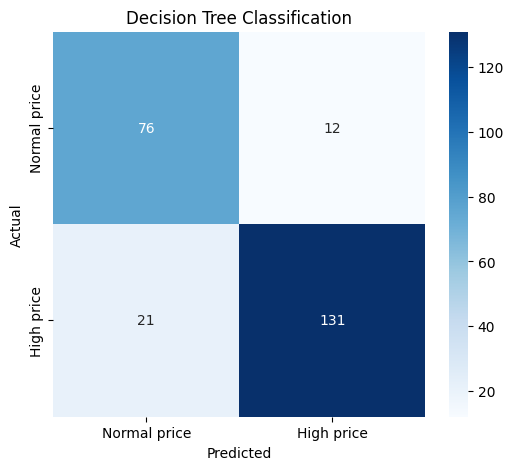

In [32]:
# ============================================
# Classification confusion matrix
# ============================================

chosen_tree_depth = 5

chosen_tree_model = tree_class_models[
    chosen_tree_depth
]

predictions_tree = chosen_tree_model.predict(
    X_test_clf
)

cm_tree = confusion_matrix(
    y_test_clf,
    predictions_tree
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal price", "High price"],
    yticklabels=["Normal price", "High price"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Classification")
plt.show()

In [33]:
# ============================================
# Random Forest classification
# ============================================

rf_class_configs = {

    "RF 100 trees": {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },

    "RF 300 trees": {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },

    "RF tuned": {
        "n_estimators": 300,
        "max_depth": 12,
        "min_samples_leaf": 2,
        "max_features": 0.7
    }
}

rf_class_results = []

rf_class_models = {}

for name, params in rf_class_configs.items():

    model = Pipeline([
        (
            "preprocessor",
            preprocessor_tree
        ),

        (
            "model",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1,
                **params
            )
        )
    ])

    results, cm = evaluate_classification(
        model,
        X_train_clf,
        X_test_clf,
        y_train_clf,
        y_test_clf
    )

    rf_class_models[name] = model

    results["Configuration"] = name

    rf_class_results.append(results)


rf_class_results_df = pd.DataFrame(
    rf_class_results
)

display(rf_class_results_df)

,Accuracy,Precision,Recall,F1,Configuration
0,0.908333,0.933333,0.921053,0.927152,RF 100 trees
1,0.904167,0.927152,0.921053,0.924092,RF 300 trees
2,0.908333,0.922078,0.934211,0.928105,RF tuned


In [34]:
# ============================================
# Logistic Regression comparison
# ============================================
# (Numerical variables scaled)

numeric_preprocessor_logistic = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    )
])

categorical_preprocessor_logistic = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),

    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        )
    )
])

preprocessor_logistic = ColumnTransformer([
    (
        "numeric",
        numeric_preprocessor_logistic,
        numeric_features
    ),

    (
        "categorical",
        categorical_preprocessor_logistic,
        categorical_features
    )
])

In [35]:
logistic_model = Pipeline([
    (
        "preprocessor",
        preprocessor_logistic
    ),

    (
        "model",
        LogisticRegression(
            max_iter=5000
        )
    )
])

logistic_results, logistic_cm = evaluate_classification(
    logistic_model,
    X_train_clf,
    X_test_clf,
    y_train_clf,
    y_test_clf
)

print(logistic_results)

{'Accuracy': 0.9291666666666667, 'Precision': 0.9411764705882353, 'Recall': 0.9473684210526315, 'F1': 0.9442622950819672}


In [36]:
# ============================================
# Classification comparison table
# ============================================

best_rf_class = rf_class_results_df.sort_values(
    "F1",
    ascending=False
).iloc[0]

best_tree_class = tree_class_results_df.sort_values(
    "F1",
    ascending=False
).iloc[0]

classification_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_results["Accuracy"],
        best_tree_class["Accuracy"],
        best_rf_class["Accuracy"]
    ],

    "Precision": [
        logistic_results["Precision"],
        best_tree_class["Precision"],
        best_rf_class["Precision"]
    ],

    "Recall": [
        logistic_results["Recall"],
        best_tree_class["Recall"],
        best_rf_class["Recall"]
    ],

    "F1": [
        logistic_results["F1"],
        best_tree_class["F1"],
        best_rf_class["F1"]
    ]
})

display(classification_comparison)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.929167,0.941176,0.947368,0.944262
1,Decision Tree,0.862500,0.916084,0.861842,0.888136
2,Random Forest,0.908333,0.922078,0.934211,0.928105


In [37]:
# ============================================
# CALCULATING FEATURE IMPORTANCE
# ============================================

# ============================================
# 1) Using the tuned regression forest
# ============================================

best_rf_reg_model = rf_reg_models["RF tuned"]

best_rf_reg_model.fit(
    X_train_reg,
    y_train_reg
)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['bedrooms', 'bathrooms',
                                                   'living_area_sqm',
                                                   'lot_size_sqm', 'year_built',
                                                   'parking_spaces',
                                                   'distance_city_center_km',
                                                   'school_rating_1_10',
                                                   'crime_rate_1_10',
                                                   'has_garden',
                                                   'has_balcony']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['city', 'neighborhood',
                                                   'property_type', 'condition',
                                                   'energy_rating'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, max_features=0.7,
                                       min_samples_leaf=2, n_estimators=300,
                                       n_jobs=-1, random_state=42))])

In [38]:
# ============================================
# 2) Getting feature names
# ============================================
feature_names = (
    best_rf_reg_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

In [39]:
# ============================================
# 3) Getting importances
# ============================================

importances = (
    best_rf_reg_model
    .named_steps["model"]
    .feature_importances_
)

In [40]:
# ============================================
# 4) Creating a table
# ============================================

importance_df = pd.DataFrame({

    "Feature": feature_names,
    "Importance": importances

})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(
    importance_df.head(10)
)

,Feature,Importance
2,numeric__living_area_sqm,0.449498
3,numeric__lot_size_sqm,0.156124
15,categorical__city_munich,0.134348
14,categorical__city_leipzig,0.037791
0,numeric__bedrooms,0.026750
6,numeric__distance_city_center_km,0.025736
4,numeric__year_built,0.019434
8,numeric__crime_rate_1_10,0.018861
7,numeric__school_rating_1_10,0.017800
32,categorical__neighborhood_maxvorstadt,0.009127


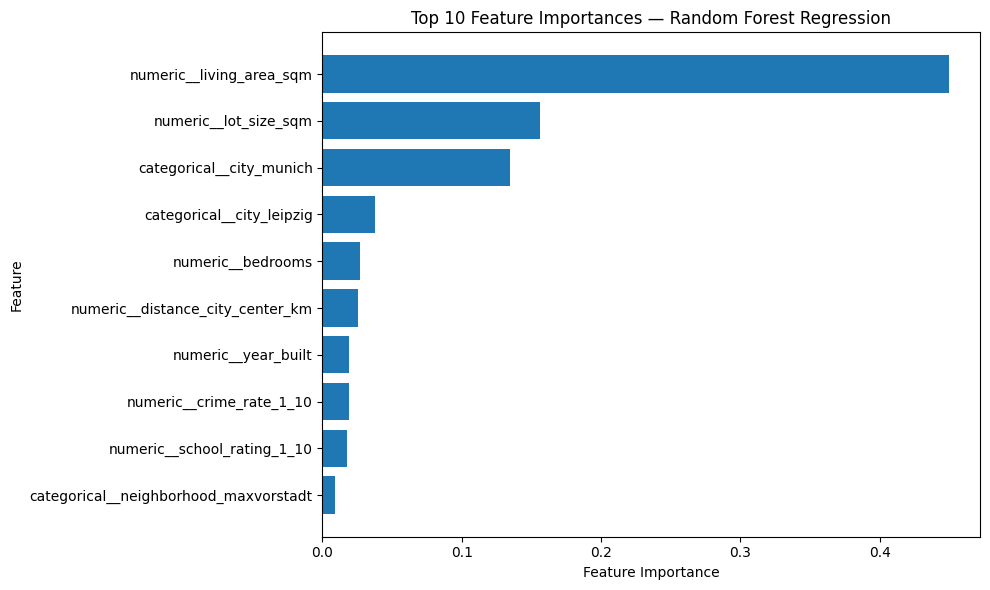

In [41]:
# ============================================
# FEATURE IMPORTANCE CHART
# ============================================

top10 = importance_df.head(10).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10["Feature"],
    top10["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top 10 Feature Importances — Random Forest Regression"
)

plt.tight_layout()
plt.show()

In [42]:
# ====================================================
# Feature importance for Random Forest classification
# ====================================================

best_rf_class_model = rf_class_models["RF tuned"]

best_rf_class_model.fit(
    X_train_clf,
    y_train_clf
)

feature_names_class = (
    best_rf_class_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances_class = (
    best_rf_class_model
    .named_steps["model"]
    .feature_importances_
)

importance_class_df = pd.DataFrame({

    "Feature": feature_names_class,
    "Importance": importances_class

}).sort_values(
    "Importance",
    ascending=False
)

display(
    importance_class_df.head(10)
)

,Feature,Importance
3,numeric__lot_size_sqm,0.325417
2,numeric__living_area_sqm,0.274034
15,categorical__city_munich,0.071103
8,numeric__crime_rate_1_10,0.036598
4,numeric__year_built,0.036317
6,numeric__distance_city_center_km,0.032189
7,numeric__school_rating_1_10,0.026923
0,numeric__bedrooms,0.023274
14,categorical__city_leipzig,0.018817
48,categorical__neighborhood_westend,0.018441


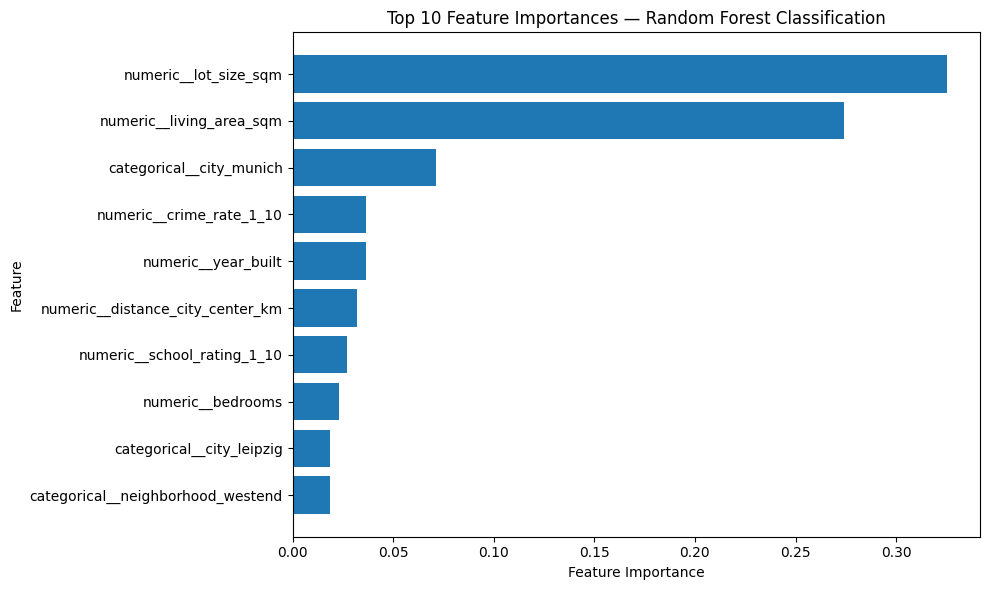

In [43]:
# ============================================
# Plotting classification feature importance
# ============================================

top10_class = (
    importance_class_df
    .head(10)
    .sort_values("Importance")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_class["Feature"],
    top10_class["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top 10 Feature Importances — Random Forest Classification"
)

plt.tight_layout()
plt.show()

In [44]:
# ==================================================
# (OPTIONAL) -- Displaying the Decision Tree itself
# ==================================================

from sklearn.tree import plot_tree

# Fit a relatively small tree so it remains readable
visual_tree = Pipeline([
    (
        "preprocessor",
        preprocessor_tree
    ),

    (
        "model",
        DecisionTreeRegressor(
            max_depth=3,
            random_state=42
        )
    )
])

visual_tree.fit(
    X_train_reg,
    y_train_reg
)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['bedrooms', 'bathrooms',
                                                   'living_area_sqm',
                                                   'lot_size_sqm', 'year_built',
                                                   'parking_spaces',
                                                   'distance_city_center_km',
                                                   'school_rating_1_10',
                                                   'crime_rate_1_10',
                                                   'has_garden',
                                                   'has_balcony']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['city', 'neighborhood',
                                                   'property_type', 'condition',
                                                   'energy_rating'])])),
                ('model', DecisionTreeRegressor(max_depth=3, random_state=42))])

In [45]:
# ==================================
# 1) Getting transformed data
# ==================================

X_train_transformed = (
    visual_tree
    .named_steps["preprocessor"]
    .transform(X_train_reg)
)

feature_names_tree = (
    visual_tree
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

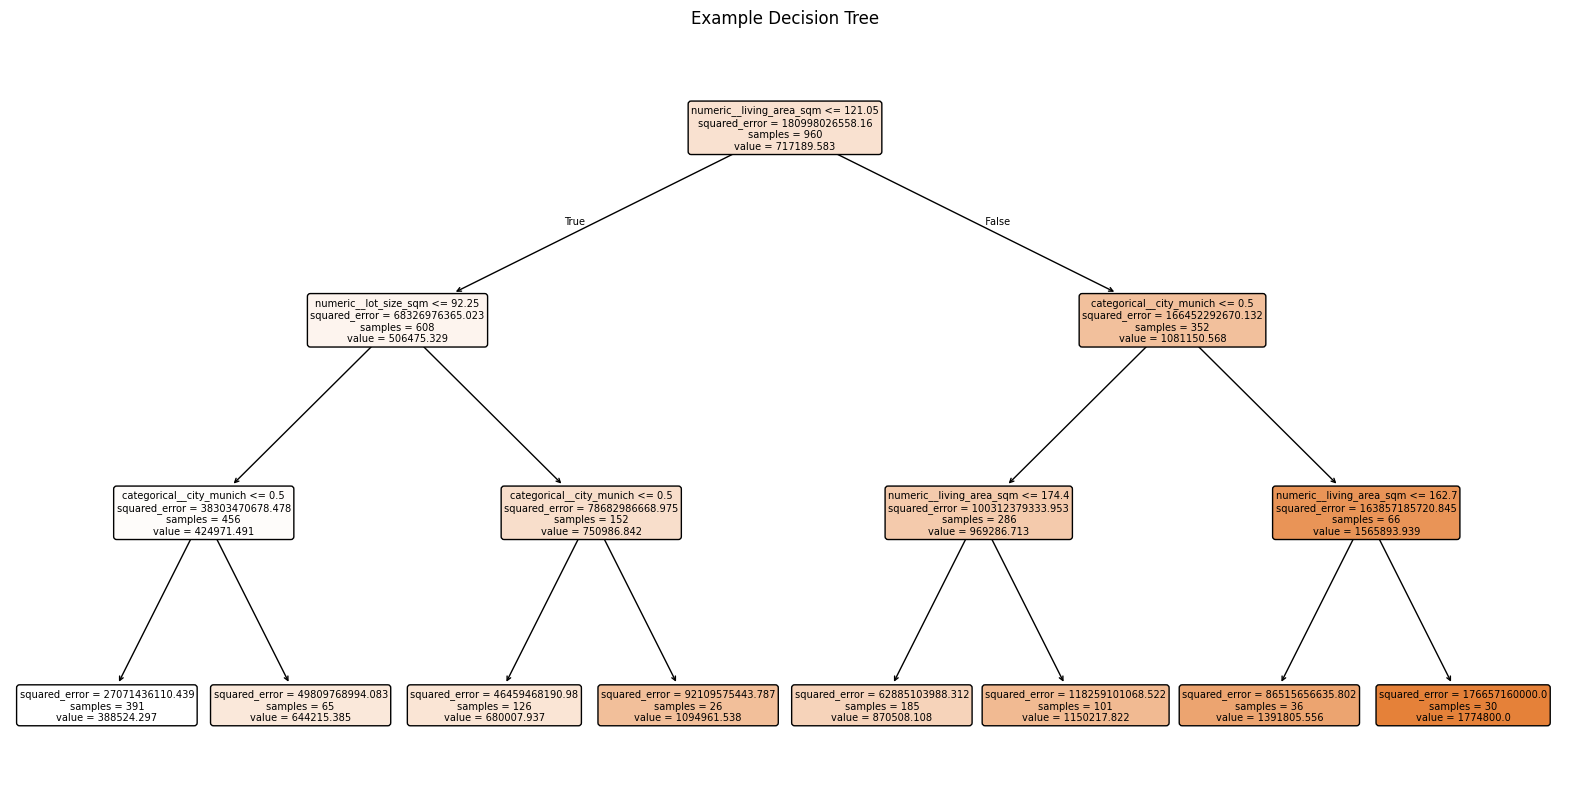

In [46]:
# ============================
# 2) Plotting
# ============================

plt.figure(figsize=(20, 10))

plot_tree(
    visual_tree.named_steps["model"],
    feature_names=feature_names_tree,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Example Decision Tree")
plt.show()

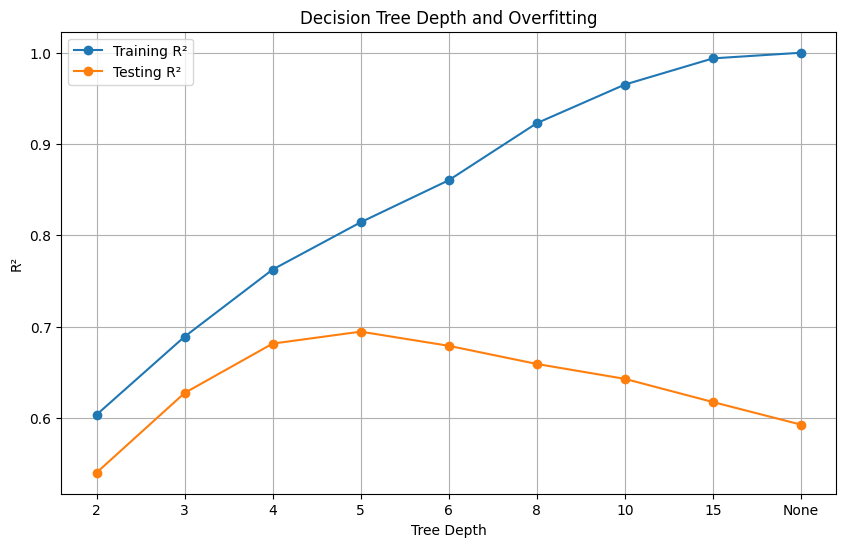

In [47]:
# =======================
# Overfitting experiment
# =======================

depths = [2, 3, 4, 5, 6, 8, 10, 15, None]

train_r2 = []
test_r2 = []

for depth in depths:

    model = Pipeline([
        (
            "preprocessor",
            preprocessor_tree
        ),

        (
            "model",
            DecisionTreeRegressor(
                max_depth=depth,
                random_state=42
            )
        )
    ])

    model.fit(
        X_train_reg,
        y_train_reg
    )

    train_pred = model.predict(X_train_reg)
    test_pred = model.predict(X_test_reg)

    train_r2.append(
        r2_score(y_train_reg, train_pred)
    )

    test_r2.append(
        r2_score(y_test_reg, test_pred)
    )

# Plotting
depth_labels = [
    "2", "3", "4", "5", "6",
    "8", "10", "15", "None"
]

plt.figure(figsize=(10, 6))

plt.plot(
    depth_labels,
    train_r2,
    marker="o",
    label="Training R²"
)

plt.plot(
    depth_labels,
    test_r2,
    marker="o",
    label="Testing R²"
)

plt.xlabel("Tree Depth")
plt.ylabel("R²")
plt.title(
    "Decision Tree Depth and Overfitting"
)

plt.legend()
plt.grid(True)

plt.show()
